In [1]:

import numpy as np
import pandas as pd
import os
import rioxarray as rxr
from osgeo import gdal
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline, make_pipeline
import geopandas as gpd
import rasterio
from shapely.geometry import box
from shapely.geometry import Point
from rasterio.sample import sample_gen
import xgboost as xgb

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from skopt import BayesSearchCV
from skopt.space import Integer, Real

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [2]:
def save_img(output_filename, reference_filename, array):
    
    reference = gdal.Open(reference_filename)
    
    # 获取地理变换参数和坐标系
    geo_transform = reference.GetGeoTransform()
    projection = reference.GetProjection()

    # 获取矩阵尺寸
    rows, cols = array.shape

    # 创建新的 TIFF 数据集
    driver = gdal.GetDriverByName('GTiff')
    out_data = driver.Create(output_filename, cols, rows, 1, gdal.GDT_Float32)

    # 设置地理变换和坐标系
    out_data.SetGeoTransform(geo_transform)
    out_data.SetProjection(projection)
    

    # 写入数据
    out_data.GetRasterBand(1).WriteArray(array)

    # 保存并关闭文件
    out_data.FlushCache()
    out_data = None

def load_refer_ICESat_point(FB_raster, icesat_csv_path, output_point, output_raw_point):
    
    df = pd.read_csv(icesat_csv_path)
    lon, lat = 'mean_lon', 'mean_lat'
    LULC_path = "E:/Downloads/tes/UK_LULC.tif"
    geometry = [Point(xy) for xy in zip(df[lon], df[lat])]
    gdf = gpd.GeoDataFrame(df, geometry=geometry)
    gdf.set_crs(epsg=4326, inplace=True)
    points = gdf
    
    with rasterio.open(FB_raster) as src:
        
        if points.crs != src.crs:
            points = points.to_crs(src.crs)
        coords = [(point.x, point.y) for point in points.geometry]
        values = list(src.sample(coords))
        
        band_count = src.count
        for band in range(band_count):
            points[f"b{band+1}_FB6"] = [v[band] for v in values]
            
    with rasterio.open(LULC_path) as src:

        if points.crs != src.crs:
            points = points.to_crs(src.crs)
        coords = [(point.x, point.y) for point in points.geometry]
        values = list(src.sample(coords))

        band_count = src.count
        points['LULC'] = [v[0] for v in values] 
     
    icesat_mask = (points['OH'] < 5) & (points['b7_FB6'] > 0)# & ((points['LULC'] == 200) | (points['LULC'] == 80))
    data = points[icesat_mask]
    
    points.to_file(output_raw_point)
    data.to_file(output_point)
    
    return data

def optimize_random_forest(x_train, y_train,  n_iter=30, cv=3):

    # if feature_columns is None:
    #     raise ValueError("feature_columns must be provided.")

    classifier = RandomForestRegressor(random_state=42)

    search_space = {
        'n_estimators': Integer(50, 500),
        'max_depth': Integer(3, 20),
        'min_samples_split': Integer(2, 20),
        'min_samples_leaf': Integer(1, 20),
        'max_features': Real(0.1, 1.0)
    }

    opt = BayesSearchCV(
        estimator=classifier,
        search_spaces=search_space,
        n_iter=n_iter,
        cv=cv,
        scoring='neg_mean_squared_error',
        random_state=42,
        n_jobs=-1
    )

    opt.fit(x_train, y_train)

    best_params = opt.best_params_
    print('Best hyperparameters:', best_params)
    print('Best score (negative MSE):', opt.best_score_)

    # 使用最优参数重新训练模型
    final_model = RandomForestRegressor(**best_params, random_state=42)
    # final_model.fit(x_train, y_train)

    return best_params, final_model


In [ ]:
#----------------  for single year -----------------
year_list = [2019, 2020, 2021, 2022, 2023, 2024]

region = 'Region2'
location = 'wash_bay'
method = 'RF'
band = 4
LULC_path = "E:/Downloads/tes/UK_LULC.tif"
LULC = rxr.open_rasterio(LULC_path, masked=True).squeeze()
target_band, target_id = ['b1_FB6','b2_FB6','b3_FB6','b4_FB6'], [0, 1, 2, 3]

for year in year_list:

    FB_raster_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_FB6_new9.tif"
    ICESAT_csv_path = f'G:\ICESat-2\{region}\{region}_{location}\A_{location}_30m_{year}_new10.csv'
    output_path = f'G:\ICESat-2\Discussion5_4\Retrieved_DEM\{location}_{year}_{band}_{method}_FB6_new9_bys_SY.tif'

    output_raw_point = f'G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_raw_new10.shp'
    output_point = f'G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.shp'
    data = load_refer_ICESat_point(FB_raster_path, ICESAT_csv_path, output_point, output_raw_point) 
    y_train = data['OH'].values
    x_train = data[target_band].values
    best_params, classifier = optimize_random_forest(x_train, y_train)
    classifier.fit(x_train, y_train)

    if not os.path.exists(FB_raster_path):
        print(FB_raster_path, 'is not exist!')
        break

    raster = rxr.open_rasterio(FB_raster_path).values
    raster = np.nan_to_num(raster, nan=0)
    selected_raster = raster[target_id, :, :]

    if len(selected_raster.shape) != 3:
        row, col = selected_raster.shape
        selected_raster = selected_raster.reshape(1, row, col)
    else: 
        bands, row, col = selected_raster.shape

    print('selected_raster.shape', selected_raster.shape)

    k = 0
    result = np.array([[]])
    for i in range(row):
            
        x_train = np.transpose(selected_raster[:, i, :])
        if method == 'RF':
            y_pred = classifier.predict(x_train)
        elif method == 'Linear':
            y_pred = np.polyval(classifier, x_train)
        else:
            y_pred = np.polyval(classifier, x_train)
            
        result = np.append(result, y_pred)
            
        if i%(int(row/5)) == 0:
                
            print(k*20 , '%_ is done')
            k = k+1
        
    result = result.reshape(row, col)
    print(result.shape, type(result))

    tf_mask = raster[6,:,:]#.flatten()
        # Freq_s2 = raster[5,:,:]#.flatten()
        
    z = rxr.open_rasterio(FB_raster_path, masked=True).squeeze() 
    LULC_aligned = LULC.rio.reproject_match(z)
        
        #result[(tf_mask == 0) | ((LULC_aligned != 200) & (LULC_aligned != 80))] = 0
    result[(tf_mask == 0)] = 0       

    save_img(output_path, FB_raster_path, result)
    print(f'{location}_{year} is output to {output_path}')

In [9]:
path_ = f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10.shp'
data = gpd.read_file(path_)
data.columns

Index(['Unnamed_ 0', 'distance', 'mean_heigh', 'mean_lon', 'mean_lat', 'OSGM',
       'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'b7_FB6', 'LULC', 'geometry'],
      dtype='object')

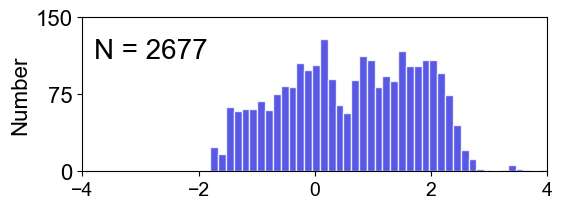

In [6]:
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'

drop_rate = 0
path_ = 'G:\ICESat-2\Discussion5_2_new\wash_bay_random_points.shp'
path_ = 'G:\ICESat-2\Discussion5_2_new\A_wash_bay_30m_2022_new10.shp'

year = 2019
path_ = f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10.shp'
data = gpd.read_file(path_)
data.columns
data = data.sort_values(by = 'OH')
n_remove = int(len(data)*drop_rate/100)
q_data = data.iloc[n_remove:]
Z_half = q_data['OH']

# 计算比例
ratio = (Z_half > 0).sum() / len(Z_half) * 100
ratio2 = (Z_half <= 0).sum() / len(Z_half) * 100
plt.figure(figsize=(6, 2))
plt.text(-3.8, 130, f"N = {len(Z_half)}", fontsize=20, ha='left', va='top')
plt.hist(Z_half, bins=50, edgecolor='white', alpha=0.8, color="#2E2EDEFF")
plt.ylabel('Number',fontsize= 16)
plt.yticks([0, 75, 150], fontsize = 16)
plt.xticks([-4, -2, 0, 2, 4], fontsize = 14)
plt.xlim(-4, 4)

# plt.axvline(0, color='blue', linestyle='--')
plt.ylim(0, 150)


# 在图中添加大于 0 的比例
# plt.text(0.5, 110, f"{ratio:.1f}%", fontsize=14, color='blue')
# plt.text(-2, 110, f"{ratio2:.1f}%", fontsize=14, color='blue')
plt.show()


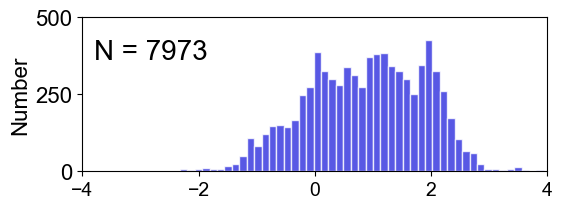

In [7]:
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'

drop_rate = 0
path_ = 'G:\ICESat-2\Discussion5_2_new\wash_bay_random_points.shp'
path_ = 'G:\ICESat-2\Discussion5_2_new\A_wash_bay_30m_2022_new10.shp'

year = 2020
path_ = f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10.shp'
data = gpd.read_file(path_)
data.columns
data = data.sort_values(by = 'OH')
n_remove = int(len(data)*drop_rate/100)
q_data = data.iloc[n_remove:]
Z_half = q_data['OH']

# 计算比例
ratio = (Z_half > 0).sum() / len(Z_half) * 100
ratio2 = (Z_half <= 0).sum() / len(Z_half) * 100
plt.figure(figsize=(6, 2))
plt.text(-3.8, 430, f"N = {len(Z_half)}", fontsize=20, ha='left', va='top')
plt.hist(Z_half, bins=50, edgecolor='white', alpha=0.8, color="#2E2EDEFF")
plt.ylabel('Number',fontsize= 16 )
plt.yticks([0, 250, 500], fontsize = 16)
plt.xticks([-4, -2, 0, 2, 4], fontsize = 14)
plt.xlim(-4, 4)

# plt.axvline(0, color='blue', linestyle='--')
plt.ylim(0, 500)


# 在图中添加大于 0 的比例
# plt.text(0.5, 110, f"{ratio:.1f}%", fontsize=14, color='blue')
# plt.text(-2, 110, f"{ratio2:.1f}%", fontsize=14, color='blue')
plt.show()

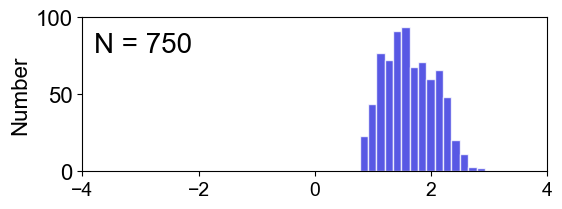

In [9]:
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'

drop_rate = 0
path_ = 'G:\ICESat-2\Discussion5_2_new\wash_bay_random_points.shp'
path_ = 'G:\ICESat-2\Discussion5_2_new\A_wash_bay_30m_2022_new10.shp'

year = 2021
path_ = f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10.shp'
data = gpd.read_file(path_)
data.columns
data = data.sort_values(by = 'OH')
n_remove = int(len(data)*drop_rate/100)
q_data = data.iloc[n_remove:]
Z_half = q_data['OH']

# 计算比例
ratio = (Z_half > 0).sum() / len(Z_half) * 100
ratio2 = (Z_half <= 0).sum() / len(Z_half) * 100
plt.figure(figsize=(6, 2))
plt.text(-3.8, 90, f"N = {len(Z_half)}", fontsize=20, ha='left', va='top')
plt.hist(Z_half, bins=15, edgecolor='white', alpha=0.8, color="#2E2EDEFF")
plt.ylabel('Number',fontsize= 16 )
plt.yticks([0, 50, 100], fontsize = 16)
plt.xticks([-4, -2, 0, 2, 4], fontsize = 14)
plt.xlim(-4, 4)

# plt.axvline(0, color='blue', linestyle='--')
plt.ylim(0, 100)


# 在图中添加大于 0 的比例
# plt.text(0.5, 110, f"{ratio:.1f}%", fontsize=14, color='blue')
# plt.text(-2, 110, f"{ratio2:.1f}%", fontsize=14, color='blue')
plt.show()

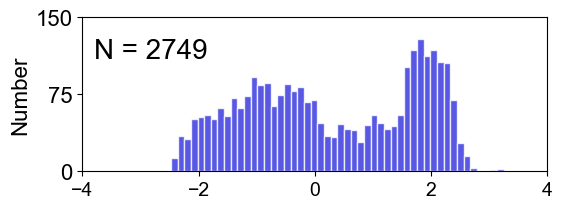

In [10]:
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'

drop_rate = 0
path_ = 'G:\ICESat-2\Discussion5_2_new\wash_bay_random_points.shp'
path_ = 'G:\ICESat-2\Discussion5_2_new\A_wash_bay_30m_2022_new10.shp'

year = 2022
path_ = f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10.shp'
data = gpd.read_file(path_)
data.columns
data = data.sort_values(by = 'OH')
n_remove = int(len(data)*drop_rate/100)
q_data = data.iloc[n_remove:]
Z_half = q_data['OH']

# 计算比例
ratio = (Z_half > 0).sum() / len(Z_half) * 100
ratio2 = (Z_half <= 0).sum() / len(Z_half) * 100
plt.figure(figsize=(6, 2))
plt.text(-3.8, 130, f"N = {2749}", fontsize=20, ha='left', va='top')
plt.hist(Z_half, bins=50, edgecolor='white', alpha=0.8, color="#2E2EDEFF")
plt.ylabel('Number',fontsize= 16 )
plt.yticks([0, 75, 150], fontsize = 16)
plt.xticks([-4, -2, 0, 2, 4], fontsize = 14)
plt.xlim(-4, 4)

# plt.axvline(0, color='blue', linestyle='--')
plt.ylim(0, 150)


# 在图中添加大于 0 的比例
# plt.text(0.5, 110, f"{ratio:.1f}%", fontsize=14, color='blue')
# plt.text(-2, 110, f"{ratio2:.1f}%", fontsize=14, color='blue')
plt.show()

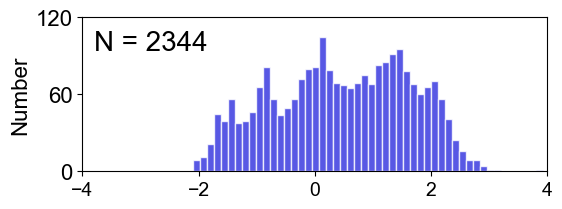

In [11]:
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'

drop_rate = 0
path_ = 'G:\ICESat-2\Discussion5_2_new\wash_bay_random_points.shp'
path_ = 'G:\ICESat-2\Discussion5_2_new\A_wash_bay_30m_2022_new10.shp'

year = 2023
path_ = f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10.shp'
data = gpd.read_file(path_)
data.columns
data = data.sort_values(by = 'OH')
n_remove = int(len(data)*drop_rate/100)
q_data = data.iloc[n_remove:]
Z_half = q_data['OH']

# 计算比例
ratio = (Z_half > 0).sum() / len(Z_half) * 100
ratio2 = (Z_half <= 0).sum() / len(Z_half) * 100
plt.figure(figsize=(6, 2))
plt.text(-3.8, 110, f"N = {len(Z_half)}", fontsize=20, ha='left', va='top')
plt.hist(Z_half, bins=50, edgecolor='white', alpha=0.8, color="#2E2EDEFF")
plt.ylabel('Number',fontsize= 16)
plt.yticks([0, 60, 120], fontsize = 16)
plt.xticks([-4, -2, 0, 2, 4], fontsize = 14)
plt.xlim(-4, 4)

# plt.axvline(0, color='blue', linestyle='--')
plt.ylim(0, 120)


# 在图中添加大于 0 的比例
# plt.text(0.5, 110, f"{ratio:.1f}%", fontsize=14, color='blue')
# plt.text(-2, 110, f"{ratio2:.1f}%", fontsize=14, color='blue')
plt.show()

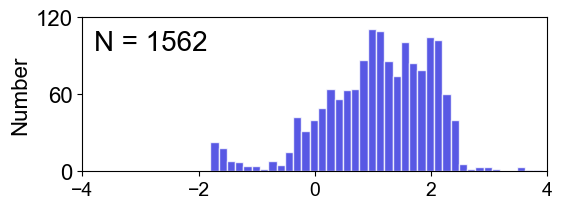

In [12]:
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'

drop_rate = 0
path_ = 'G:\ICESat-2\Discussion5_2_new\wash_bay_random_points.shp'
path_ = 'G:\ICESat-2\Discussion5_2_new\A_wash_bay_30m_2022_new10.shp'

year = 2024
path_ = f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10.shp'
data = gpd.read_file(path_)
data.columns
data = data.sort_values(by = 'OH')
n_remove = int(len(data)*drop_rate/100)
q_data = data.iloc[n_remove:]
Z_half = q_data['OH']

# 计算比例
ratio = (Z_half > 0).sum() / len(Z_half) * 100
ratio2 = (Z_half <= 0).sum() / len(Z_half) * 100
plt.figure(figsize=(6, 2))
plt.text(-3.8, 110, f"N = {len(Z_half)}", fontsize=20, ha='left', va='top')
plt.hist(Z_half, bins=40, edgecolor='white', alpha=0.8, color="#2E2EDEFF")
plt.ylabel('Number',fontsize= 16)
plt.yticks([0, 60, 120], fontsize = 16)
plt.xticks([-4, -2, 0, 2, 4], fontsize = 14)
plt.xlim(-4, 4)

# plt.axvline(0, color='blue', linestyle='--')
plt.ylim(0, 120)


# 在图中添加大于 0 的比例
# plt.text(0.5, 110, f"{ratio:.1f}%", fontsize=14, color='blue')
# plt.text(-2, 110, f"{ratio2:.1f}%", fontsize=14, color='blue')
plt.show()

In [ ]:

points_path = r'G:\ICESat-2\Discussion51_new\Validation_point_wash.shp'
out_points_path = r'G:\ICESat-2\Discussion51_new\Validation_point_wash.shp'
points = gpd.read_file(points_path)

year_list = [2019, 2020, 2021, 2022, 2023, 2024]

for year in year_list:
      
    raster_path = f'G:\ICESat-2\Discussion5_4\Retrieved_DEM\wash_bay_{year}_{4}_RF_FB6_new9_bys_SY.tif'

    with rasterio.open(raster_path) as src:
            
        raster_crs = src.crs
        if points.crs != raster_crs:
            points = points.to_crs(raster_crs)
                
        coords = [(geom.x, geom.y) for geom in points.geometry]
        values = list(src.sample(coords))
            
        band_values = [val[0] for val in values]
                
        points[f'B{band}_{num[j]}_{No[i]}'] = band_values

points.to_file(out_points_path)

2020

In [11]:

year_list = [2020, 2021, 2022, 2024]

for year in year_list:
      
      
    points_path = f'G:\ICESat-2\Region3_map\Region3c_map\A{year}\A_Region3c_30m_{year}_new10_kk.shp'
    out_points_path = f'G:\ICESat-2\Region3_map\Region3c_map\A{year}\A_Region3c_30m_{year}_new10_kk.shp'
    # raster_path = f'G:\ICESat-2\Discussion5_4\Retrieved_DEM\wash_bay_{year}_{4}_RF_FB6_new9_bys_SY.tif'
    raster_path = f'G:\DTM_ref\Region3c\Region3c_{year}\Region3c_masked_{year}.tif'
    points = gpd.read_file(points_path)
    
    with rasterio.open(raster_path) as src:
            
        raster_crs = src.crs
        if points.crs != raster_crs:
            points = points.to_crs(raster_crs)
                
        coords = [(geom.x, geom.y) for geom in points.geometry]
        values = list(src.sample(coords))
            
        band_values = [val[0] for val in values]
                
        points[f'Ref_dem'] = band_values

    points.to_file(out_points_path)

In [10]:
year_list = [2020, 2021, 2022, 2024]

for year in year_list:
      
      
    points_path = f'G:\ICESat-2\Region3_map\Region3c_map\A{year}\A_Region3c_30m_{year}_new10_kk.shp'
    out_points_path = f'G:\ICESat-2\Region3_map\Region3c_map\A{year}\A_Region3c_30m_{year}_new10_kk.shp'
    # raster_path = f'G:\ICESat-2\Discussion5_4\Retrieved_DEM\wash_bay_{year}_{4}_RF_FB6_new9_bys_SY.tif'
    # raster_path = f'G:\DTM_ref\Region3c\Region3c_{year}\Region3c_masked_{year}.tif'
    rater_path = f'G:\ICESat-2\Region3_map\Region3c_map\A{year}\Region3c_{year}_4_RF_FB6_new9_bys.tif'
    points = gpd.read_file(points_path)
    
    with rasterio.open(raster_path) as src:
            
        raster_crs = src.crs
        if points.crs != raster_crs:
            points = points.to_crs(raster_crs)
                
        coords = [(geom.x, geom.y) for geom in points.geometry]
        values = list(src.sample(coords))
            
        band_values = [val[0] for val in values]
                
        points[f'Re_dem'] = band_values

    points.to_file(out_points_path)